# Techo de mejora: el minimo de pasillos por batch

**Pregunta.** Cuanto se puede ganar, como maximo, sobre el greedy por demanda si el picker recorre
en S.

**Idea.** En un recorrido en S cada pasillo que tiene al menos un pick se atraviesa entero. Entonces
la distancia de un batch depende de **cuantos pasillos visita y cuales**, no de donde esta cada
producto dentro del pasillo. El slotting solo puede bajar ese numero. El minimo posible se obtiene
resolviendo un problema de optimizacion: asignar productos a pasillos, respetando la capacidad de
cada pasillo, para que los batches entren a la menor cantidad de pasillos.

**Plan del notebook.**
1. Escribir las dos formas de medir la ruta (la del evaluador y la S estricta) y compararlas.
2. Formular el problema de asignacion a pasillos y resolverlo con el solver.
3. Comparar sobre test: slotting vigente, greedy, asignacion aprendida de train y oraculo.

## 0. Configuracion y datos

In [1]:
# Librerias y piezas del paquete que se usan en este notebook.
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from abs_affinity_based_slotting.config import dataset_dir, DOCK, make_solver_env
from abs_affinity_based_slotting.data import WarehouseDataLoader, split_picking_events
from abs_affinity_based_slotting.demand import TopKFilter
from abs_affinity_based_slotting.slotting import build_full_instance, Assignment
from abs_affinity_based_slotting.methods import method_registry
from abs_affinity_based_slotting.evaluation import bay_snake_keys, snake_order, route_distance

pd.set_option("display.width", 160)

SIZE = "big"          # deposito de v2: small | medium | big
TIME_LIMIT = 1200     # segundos que se le dan al solver por cada problema
NOREL_TIME = 600      # de esos, cuantos van a la heuristica sin relajacion (busca soluciones antes de resolver el LP)

In [2]:
# Datos: las cinco tablas, el corte train/test por batch y la instancia del problema.
# La instancia solo se usa aca por sus indices (SKU <-> ubicacion <-> bay) y por la demanda f.
ds = WarehouseDataLoader(dataset_dir("v2", SIZE)).load_all()
split = split_picking_events(ds.picking_events, test_size=0.2)
instance = build_full_instance(split.train, ds.initial_stock, ds.distances, affinity_metric="jaccard",
                               cooccurrence_col="order_id", affinity_filter=TopKFilter(k=10), normalize=True)
print(instance)
print("batches de train:", split.train["batch_id"].nunique(), "| batches de test:", split.test["batch_id"].nunique())

SlottingInstance(n_skus=24883, n_locations=27648, n_bays=769, affinity_edges=332168)
batches de train: 14480 | batches de test: 3620


In [3]:
# Geometria de los pasillos, sacada de la tabla de coordenadas.
coord = ds.coordinates.set_index("bay_id")
bays = ds.coordinates.dropna(subset=["aisle"]).copy()     # todas las bays menos el dock
bays["aisle"] = bays["aisle"].astype(int)

aisles = np.sort(bays["aisle"].unique())                   # numeros de pasillo, ej. [1, 2, 3, 4]
n_aisles = len(aisles)
aisle_x = bays.groupby("aisle")["x"].mean()                # coordenada lateral de cada pasillo (centro)
y0, y1 = float(bays["y"].min()), float(bays["y"].max())    # donde empieza y termina un pasillo
pitch = float(np.min(np.diff(np.sort(bays["y"].unique()))))  # separacion entre bays consecutivas
L = y1 - y0 + pitch                                        # largo de un pasillo, lo que cuesta atravesarlo
dock_xy = coord.loc[DOCK, ["x", "y"]].to_numpy(dtype=float)

print(f"{n_aisles} pasillos | largo L = {L:.0f} pulgadas | lateral x de cada pasillo: {aisle_x.round(0).tolist()}")
print(f"dock en x={dock_xy[0]:.0f}, y={dock_xy[1]:.0f}; los pasillos van de y={y0:.0f} a y={y1:.0f}")

16 pasillos | largo L = 2664 pulgadas | lateral x de cada pasillo: [96.0, 288.0, 480.0, 672.0, 864.0, 1056.0, 1248.0, 1440.0, 1632.0, 1824.0, 2016.0, 2208.0, 2400.0, 2592.0, 2784.0, 2976.0]
dock en x=0, y=-200; los pasillos van de y=168 a y=2736


In [4]:
# Traduccion de la geometria a los indices de la instancia, para poder pasar de un plan a pasillos.
bay_aisle = coord["aisle"].reindex(instance.bay_ids).to_numpy(dtype=float)   # pasillo de cada bay (NaN en el dock)
loc_aisle = bay_aisle[instance.location_bay].astype(int)                     # pasillo de cada ubicacion
capacity = pd.Series(loc_aisle).value_counts().sort_index()                  # ubicaciones por pasillo = capacidad
snake_keys = bay_snake_keys(ds.coordinates, instance.bay_ids)                # orden serpenteante que usa el evaluador
dock = instance.bay_index(DOCK)

print("capacidad por pasillo:", capacity.to_dict())

capacidad por pasillo: {1: 1728, 2: 1728, 3: 1728, 4: 1728, 5: 1728, 6: 1728, 7: 1728, 8: 1728, 9: 1728, 10: 1728, 11: 1728, 12: 1728, 13: 1728, 14: 1728, 15: 1728, 16: 1728}


## 1. Dos formas de medir la ruta de un batch

Notacion. $B(b)$ es el conjunto de bays que el batch $b$ tiene que visitar (depende del plan).
$\mathcal{A}(b) = \{a_1 < \dots < a_m\}$ son los pasillos donde caen esas bays. $x_a$ es la
coordenada lateral del pasillo $a$, $L$ el largo de un pasillo y $D(\cdot,\cdot)$ la distancia
caminada entre dos bays segun la tabla del dataset.

**Evaluador vigente, $R_E$.** Ordena las bays por (pasillo, numero de bay) y suma la distancia
caminada entre cada par consecutivo, mas la ida y la vuelta al dock:
$$R_E(b) = D(\text{dock}, \beta_1) + \sum_{t=1}^{T-1} D(\beta_t, \beta_{t+1}) + D(\beta_T, \text{dock}).$$
Como usa el camino mas corto entre el ultimo pick de un pasillo y el primero del siguiente,
**vuelve por el frente**: en cada pasillo entra hasta el pick mas lejano y sale por donde entro.

**S estricto, $R_S$.** El picker entra al primer pasillo con picks, lo atraviesa completo, cruza
al siguiente, lo atraviesa en sentido contrario, y asi hasta el ultimo; si atraveso una cantidad
impar de pasillos termina en el fondo y baja por el frente para volver:
$$R_S(b) = d_0(a_1) + m\,L + \sum_{k=1}^{m-1} |x_{a_{k+1}} - x_{a_k}| + [\,m \text{ impar}\,]\,L + d_0(a_m),$$
con $d_0(a) = |x_a - x_{\text{dock}}| + (y_0 - y_{\text{dock}})$ la distancia del dock al frente del
pasillo $a$. **Depende solo de que pasillos se visitan**, no de la posicion dentro de ellos.

In [5]:
def bays_del_batch(assignment, skus):
    """Bays que hay que visitar para recolectar estos SKUs con este plan (indices de bay, sin repetir)."""
    locs = [instance.location_index(assignment.location_of(s)) for s in skus]
    return np.unique(instance.location_bay[locs])


def pasillos_de(bays_idx):
    """Pasillos distintos donde caen esas bays, ordenados."""
    return sorted(set(bay_aisle[bays_idx].astype(int)))

In [6]:
def ruta_evaluador(bays_idx):
    """R_E: la misma cuenta que hace Evaluator y Simulator en el paquete."""
    return route_distance(snake_order(bays_idx, snake_keys[bays_idx]), instance.bay_distance, dock)


def ruta_s(pasillos):
    """R_S: recorrido en S estricto sobre la lista ordenada de pasillos visitados."""
    d0 = lambda a: abs(aisle_x.loc[a] - dock_xy[0]) + (y0 - dock_xy[1])   # dock -> frente del pasillo a
    m = len(pasillos)
    lateral = sum(abs(aisle_x.loc[pasillos[k + 1]] - aisle_x.loc[pasillos[k]]) for k in range(m - 1))
    vuelta_por_el_frente = L if m % 2 == 1 else 0.0
    return d0(pasillos[0]) + m * L + lateral + vuelta_por_el_frente + d0(pasillos[-1])


def profundidad(bays_idx, pasillos):
    """Hasta donde se entra en cada pasillo visitado (pick mas lejano), promedio en pulgadas.
    Es lo que R_E cobra y R_S no."""
    return float(np.mean([coord["y"].reindex(instance.bay_ids[bays_idx[bay_aisle[bays_idx] == a]]).max() - y0 + pitch
                          for a in pasillos]))

In [7]:
def medir(assignment, picking):
    """Una fila por batch: cuantos pasillos visita, R_E, R_S y profundidad, con este plan."""
    rows = []
    for batch_id, g in picking.groupby("batch_id", sort=False):
        b = bays_del_batch(assignment, g["sku"].unique())
        A = pasillos_de(b)
        rows.append({"batch_id": batch_id, "pasillos": len(A), "R_E": ruta_evaluador(b),
                     "R_S": ruta_s(A), "profundidad": profundidad(b, A)})
    return pd.DataFrame(rows).set_index("batch_id")


def resumen(nombre, medidas):
    """Promedios sobre los batches, para las tablas comparativas."""
    return {"plan": nombre, "pasillos/batch": round(medidas["pasillos"].mean(), 2),
            "R_E media": round(medidas["R_E"].mean()), "R_S media": round(medidas["R_S"].mean()),
            "profundidad media": round(medidas["profundidad"].mean())}

Se miden los dos planes de referencia sobre los batches de test: el slotting vigente y el greedy
por demanda (SKUs por demanda descendente contra ubicaciones por distancia al dock ascendente).

In [8]:
current = method_registry.get("current")(ds.initial_stock).solve(instance)
greedy = method_registry.get("demand_greedy")().solve(instance)

m_cur = medir(current, split.test)
m_gre = medir(greedy, split.test)
pd.DataFrame([resumen("current", m_cur), resumen("demand_greedy", m_gre)]).set_index("plan")

,pasillos/batch,R_E media,R_S media,profundidad media
plan,,,,
current,15.93,45246,49298,2279
demand_greedy,12.62,27714,41211,1374


Que explica a cada medida. Si $R_E$ sigue a la profundidad y $R_S$ a la cantidad de pasillos,
las dos politicas premian cosas distintas del slotting.

In [9]:
m_ambos = pd.concat([m_cur, m_gre])
print("correlacion de R_E con la profundidad :", round(m_ambos["R_E"].corr(m_ambos["profundidad"]), 3))
print("correlacion de R_E con los pasillos   :", round(m_ambos["R_E"].corr(m_ambos["pasillos"]), 3))
print("correlacion de R_S con los pasillos   :", round(m_ambos["R_S"].corr(m_ambos["pasillos"]), 3))

correlacion de R_E con la profundidad : 0.954
correlacion de R_E con los pasillos   : 0.886
correlacion de R_S con los pasillos   : 0.973


## 2. El problema: asignar productos a pasillos

**Conjuntos.** $I$ productos. $\mathcal{A}$ pasillos. $\mathcal{B}$ batches; $I_b \subseteq I$ los
productos que pide el batch $b$.

**Parametros.** $\kappa_a$, cantidad de ubicaciones del pasillo $a$ (su capacidad).
$w_a = L + 2\,|x_a - x_{\text{dock}}|$, lo que cuesta entrar al pasillo $a$: atravesarlo mas ir y
volver lateralmente hasta el.

**Variables.** $x_{ia} \in \{0,1\}$ vale 1 si el producto $i$ va al pasillo $a$.
$y_{ba} \in \{0,1\}$ vale 1 si el batch $b$ tiene que entrar al pasillo $a$.

$$
\begin{aligned}
\min_{x,\,y}\quad & \sum_{b \in \mathcal{B}} \sum_{a \in \mathcal{A}} w_a\, y_{ba}
    && \text{(costo total de los pasillos que entran todos los batches)} \\
\text{s.a.}\quad & \sum_{a \in \mathcal{A}} x_{ia} = 1 && \forall i \in I
    \quad \text{(cada producto en un pasillo)} \\
& \sum_{i \in I} x_{ia} \le \kappa_a && \forall a \in \mathcal{A}
    \quad \text{(capacidad del pasillo)} \\
& |I_b|\, y_{ba} \ge \sum_{i \in I_b} x_{ia} && \forall b \in \mathcal{B},\ a \in \mathcal{A}
    \quad \text{(si algun producto de } b \text{ esta en } a\text{, } b \text{ entra a } a\text{)} \\
& x_{ia},\, y_{ba} \in \{0,1\}.
\end{aligned}
$$

Tres observaciones.
- El objetivo es $\sum_b R_S(b)$ salvo por el lateral, que aca se cuenta como ida y vuelta al
  pasillo en vez de entre pasillos consecutivos. Es una aproximacion que hace lineal el problema.
- La tercera restriccion, con $y$ binaria, equivale a pedir $y_{ba} \ge x_{ia}$ para cada
  producto del batch, pero con una sola restriccion por par (batch, pasillo).
- La solucion dice un pasillo por producto. Dentro del pasillo el recorrido en S no distingue
  posiciones, asi que los productos se ordenan por demanda desde el frente.

**Dos usos del mismo problema.** Resuelto sobre los batches de **train** es un metodo: aprende
del pasado y se evalua en test. Resuelto sobre los batches de **test** es un **oraculo**: conoce
los pedidos que va a servir, y por eso es el techo de lo que cualquier asignacion a pasillos puede
lograr en ese test. El solver corre con un limite de tiempo; si no cierra el gap, la solucion es
factible pero no probada optima, y el techo verdadero es al menos tan bueno como ella.

Primero los datos del problema: que productos pide cada batch, en indices de la instancia.

In [10]:
def datos_del_problema(picking):
    """De las lineas de picking a los conjuntos I_b, como matriz de incidencia dispersa M (batches x productos).
    M[b, i] = 1 si el producto i esta en el batch b. La fila b es I_b."""
    pares = picking[["batch_id", "sku"]].drop_duplicates()              # un producto cuenta una vez por batch
    i = pares["sku"].map(instance.sku_indexes).to_numpy()                # id de SKU -> indice de la instancia
    b = pd.factorize(pares["batch_id"])[0]                               # id de batch -> 0..B-1
    return sparse.csr_matrix((np.ones(len(i)), (b, i)), shape=(b.max() + 1, instance.n_skus))


w = np.array([L + 2.0 * abs(float(aisle_x.loc[a]) - dock_xy[0]) for a in aisles])   # w_a: costo de entrar a cada pasillo
kappa = capacity.loc[aisles].to_numpy()                                                # kappa_a: capacidad de cada pasillo
print("w_a por pasillo (pulgadas):", dict(zip(aisles.tolist(), w.round().astype(int).tolist())))

w_a por pasillo (pulgadas): {1: 2856, 2: 3240, 3: 3624, 4: 4008, 5: 4392, 6: 4776, 7: 5160, 8: 5544, 9: 5928, 10: 6312, 11: 6696, 12: 7080, 13: 7464, 14: 7848, 15: 8232, 16: 8616}


Despues el modelo, escrito tal como esta arriba, y su resolucion con el solver. El solver arranca
de una solucion inicial (llenar los pasillos por demanda descendente, el punto de partida mas
simple) y dedica la primera parte del tiempo a buscar soluciones enteras sin resolver la
relajacion lineal, porque en estos problemas la relajacion es muy debil y muy lenta.

In [11]:
def solucion_inicial():
    """Punto de partida para el solver: los productos por demanda descendente llenan los pasillos en orden."""
    orden = np.argsort(-instance.demand, kind="stable")
    pasillo = np.empty(instance.n_skus, dtype=int)
    pasillo[orden] = np.repeat(np.arange(n_aisles), kappa)[:instance.n_skus]
    return pasillo


def costo_pasillos(M, pasillo):
    """La funcion objetivo de la seccion 2 evaluada en una asignacion producto -> pasillo (para chequear al solver)."""
    X = sparse.csr_matrix((np.ones(instance.n_skus), (np.arange(instance.n_skus), pasillo)), shape=(instance.n_skus, n_aisles))
    entra = (M @ X).toarray() > 0                          # entra[b, a]: el batch b tiene algun producto en el pasillo a
    return float((entra * w).sum())


def resolver_asignacion_a_pasillos(picking, time_limit=TIME_LIMIT, norel_time=NOREL_TIME):
    """Arma y resuelve el problema de la seccion 2 sobre los batches de `picking`.
    Devuelve (pasillo asignado a cada indice de SKU, resumen de la corrida del solver)."""
    import gurobipy as gp
    from gurobipy import GRB

    M = datos_del_problema(picking)                        # M[b, i]: incidencia batch x producto
    n_batches = M.shape[0]
    tam = np.asarray(M.sum(axis=1)).ravel()                # |I_b|

    modelo = gp.Model("pasillos", env=make_solver_env())   # la licencia sale del .env
    modelo.Params.OutputFlag = 0
    modelo.Params.TimeLimit = time_limit
    modelo.Params.NoRelHeurTime = norel_time               # primero heuristica sin relajacion
    modelo.Params.MIPFocus = 1                             # despues, prioridad a encontrar mejores soluciones

    # variables
    x = modelo.addMVar((instance.n_skus, n_aisles), vtype=GRB.BINARY, name="x")   # x[i, a]
    y = modelo.addMVar((n_batches, n_aisles), vtype=GRB.BINARY, name="y")         # y[b, a]

    # restricciones
    modelo.addConstr(x.sum(axis=1) == 1, name="un_pasillo_por_producto")
    modelo.addConstr(x.sum(axis=0) <= kappa, name="capacidad")
    modelo.addConstr(y * tam[:, None] >= M @ x, name="el_batch_entra_al_pasillo")   # |I_b| y_ba >= sum_{i in I_b} x_ia

    # objetivo
    modelo.setObjective((y @ w).sum(), GRB.MINIMIZE)

    # punto de partida
    inicial = solucion_inicial()
    X0 = np.zeros((instance.n_skus, n_aisles)); X0[np.arange(instance.n_skus), inicial] = 1.0
    x.Start = X0

    t0 = time.time()
    modelo.optimize()

    # lectura de la solucion: el pasillo a con x[i, a] = 1 para cada producto i
    pasillo = np.argmax(x.X, axis=1)
    assert abs(costo_pasillos(M, pasillo) - modelo.ObjVal) < 1e-6 * modelo.ObjVal   # el objetivo coincide con la cuenta directa
    info = {"batches": n_batches, "variables": modelo.NumVars, "restricciones": modelo.NumConstrs,
            "segundos": round(time.time() - t0), "objetivo inicial": round(costo_pasillos(M, inicial)),
            "objetivo": round(modelo.ObjVal), "cota inferior": round(modelo.ObjBound),
            "gap": f"{100 * modelo.MIPGap:.0f}%", "optimo probado": modelo.Status == GRB.OPTIMAL}
    return pasillo, info

Y el paso de la solucion (un pasillo por producto) a un plan completo (una ubicacion por producto).

In [12]:
def plan_desde_pasillos(pasillo):
    """Dentro de cada pasillo, los productos de mayor demanda van a las ubicaciones mas cercanas al frente."""
    mapping = {}
    for a in range(n_aisles):
        skus = np.flatnonzero(pasillo == a)
        skus = skus[np.argsort(-instance.demand[skus], kind="stable")]              # por demanda descendente
        locs = np.flatnonzero(loc_aisle == aisles[a])
        locs = locs[np.argsort(instance.location_cost[locs], kind="stable")]         # por distancia al dock ascendente
        for s, l in zip(skus, locs):
            mapping[instance.sku_id(s)] = instance.location_id(l)
    return Assignment(mapping)

## 3. Aprendido de train, evaluado en test

El problema se resuelve con los batches de train. El plan resultante se mide sobre test, igual
que cualquier otro metodo.

In [13]:
pasillo_train, info_train = resolver_asignacion_a_pasillos(split.train)
plan_train = plan_desde_pasillos(pasillo_train)
m_train = medir(plan_train, split.test)

print(info_train)
print("SKUs por pasillo            :", np.bincount(pasillo_train, minlength=n_aisles).tolist())
print("fraccion de la demanda por pasillo:", np.round([instance.demand[pasillo_train == a].sum() for a in range(n_aisles)], 3).tolist())

Set parameter WLSAccessID


Set parameter WLSSecret


Set parameter LicenseID to value 2805866


Academic license 2805866 - for non-commercial use only - registered to sa___@mi.unc.edu.ar


{'batches': 14480, 'variables': 629808, 'restricciones': 256579, 'segundos': 1201, 'objetivo inicial': 792328224, 'objetivo': 704997624, 'cota inferior': 49611170, 'gap': '93%', 'optimo probado': False}
SKUs por pasillo            : [1728, 1728, 1728, 1728, 1728, 1728, 1728, 1728, 1728, 1728, 1728, 1728, 1728, 1728, 689, 2]
fraccion de la demanda por pasillo: [0.606, 0.134, 0.062, 0.041, 0.03, 0.024, 0.02, 0.017, 0.014, 0.013, 0.011, 0.01, 0.009, 0.007, 0.002, 0.0]


## 4. Oraculo sobre test

El mismo problema, resuelto con los batches de test. No es un metodo aplicable, es la cota.

In [14]:
pasillo_test, info_test = resolver_asignacion_a_pasillos(split.test)
plan_oraculo = plan_desde_pasillos(pasillo_test)
m_ora = medir(plan_oraculo, split.test)

print(info_test)

Set parameter WLSAccessID


Set parameter WLSSecret


Set parameter LicenseID to value 2805866


Academic license 2805866 - for non-commercial use only - registered to sa___@mi.unc.edu.ar


{'batches': 3620, 'variables': 456048, 'restricciones': 82819, 'segundos': 20016, 'objetivo inicial': 210548976, 'objetivo': 124213632, 'cota inferior': 12271680, 'gap': '90%', 'optimo probado': False}


## 5. Comparacion sobre los batches de test

Los cuatro planes, medidos con las dos politicas de ruteo. La columna "vs greedy" es la
diferencia porcentual contra el greedy por demanda bajo cada medida.

In [15]:
tabla = pd.DataFrame([resumen("current", m_cur), resumen("demand_greedy", m_gre),
                      resumen("pasillos aprendidos de train", m_train),
                      resumen("oraculo sobre test", m_ora)]).set_index("plan")
for col in ("R_E media", "R_S media"):
    base = tabla.loc["demand_greedy", col]
    tabla[f"{col} vs greedy"] = ((tabla[col] - base) / base * 100).round(1).astype(str) + "%"
tabla

,pasillos/batch,R_E media,R_S media,profundidad media,R_E media vs greedy,R_S media vs greedy
plan,,,,,,
current,15.93,45246,49298,2279,63.3%,19.6%
demand_greedy,12.62,27714,41211,1374,0.0%,0.0%
pasillos aprendidos de train,11.44,27941,37662,1774,0.8%,-8.6%
oraculo sobre test,7.57,24243,26350,2094,-12.5%,-36.1%


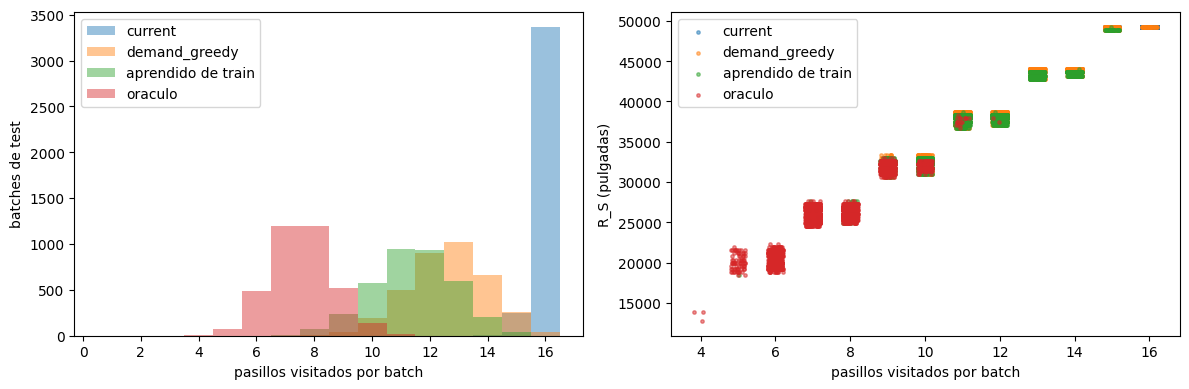

In [16]:
# Izquierda: cuantos pasillos visita cada batch con cada plan. Derecha: R_S es una funcion de ese numero.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
planes = (("current", m_cur), ("demand_greedy", m_gre), ("aprendido de train", m_train), ("oraculo", m_ora))
for nombre, mm in planes:
    axes[0].hist(mm["pasillos"], bins=np.arange(0.5, n_aisles + 1.5), alpha=0.45, label=nombre)
    axes[1].scatter(mm["pasillos"] + np.random.default_rng(0).uniform(-0.2, 0.2, len(mm)), mm["R_S"], s=6, alpha=0.5, label=nombre)
axes[0].set_xlabel("pasillos visitados por batch"); axes[0].set_ylabel("batches de test"); axes[0].legend()
axes[1].set_xlabel("pasillos visitados por batch"); axes[1].set_ylabel("R_S (pulgadas)"); axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Lectura (`big`: 16 pasillos, 24.883 productos, 14.480 batches de train y 3.620 de test)

**Las dos medidas premian cosas distintas.** $R_E$ correlaciona 0,95 con la profundidad a la que
se entra en cada pasillo; $R_S$ correlaciona 0,97 con la cantidad de pasillos (no es 1 porque el
lateral depende de cuales). Bajo $R_E$ el greedy le gana al slotting vigente por 39% (27.714
contra 45.246) porque acorta la profundidad de 2.279 a 1.374 pulgadas. Bajo $R_S$ la ventaja es
16% (41.211 contra 49.298) y viene de visitar 12,6 pasillos por batch en vez de 15,9.

**El techo.** El oraculo baja a 7,57 pasillos por batch y da 26.350 pulgadas bajo $R_S$, un 36%
menos que el greedy; bajo $R_E$ tambien gana, 12,5%. El solver no probo optimalidad: la cota
inferior es 12,3 M contra un objetivo de 124,2 M (gap 90%). Esa cota es la relajacion lineal, que
reparte cada producto en fracciones 1/16 por pasillo y hace que cada batch "entre" a un pasillo
en total: no dice nada sobre el minimo real. Entonces 26.350 es una cota superior del minimo
alcanzable, y el margen sobre el greedy es de **al menos 36%** con recorrido en S y batches de
25 ordenes. El numero exacto no se puede obtener con esta formulacion: en `small`, con 218
batches, el gap ya queda en 60%.

**Lo aprendido de train.** El plan resuelto sobre los batches de train visita 11,44 pasillos por
batch en test y le gana al greedy por 8,6% bajo $R_S$ (37.662 contra 41.211), empatando bajo
$R_E$. Lo logra concentrando el 61% de la demanda en el pasillo 1 y el 74% en los dos primeros,
mientras el greedy reparte los populares por el frente de todos los pasillos. La distancia entre
11,44 y 7,57 es lo que se gana conociendo que productos vienen juntos en cada batch de test: parte
es co-demanda que train no contiene, parte es el solver, que tambien esta lejos del optimo en
train (gap 93%).

**Sobre el solver.** El punto de partida (llenar pasillos por demanda) vale 792 M en train y
211 M en test; la heuristica sin relajacion lo baja a 705 M y 124 M. Sin ella, en una corrida
anterior con el mismo limite el solver devolvia 792 M y 159 M. En test el reloj marco 20.016 s
en vez de 1.200 porque el limite es de tiempo de pared y la maquina estuvo suspendida durante la
corrida; en una corrida de prueba de 1.200 s el resultado fue 126,6 M, casi el mismo.

**Consecuencias.**
1. Los resultados de la tesis dependen de la politica de ruteo del evaluador, y Mariano confirmo
   que la operacion recorre en S. Hay que agregar $R_S$ al evaluador y al simulador como politica
   elegible y volver a medir todo con ella.
2. Bajo $R_S$ el objetivo pasa a ser el numero de pasillos por batch. El problema de la seccion 2
   es la formulacion natural de ese objetivo, y el termino cuadratico con la distancia `aisle`
   es su version continua. Resuelto sobre train ya es un metodo que le gana al greedy en `big`.
3. El margen restante (de 8,6% a por lo menos 36%) requiere senal de co-demanda entre productos o
   un mejor metodo de resolucion, y las dos cosas se pueden atacar por separado.
4. En `small` (4 pasillos) el mismo experimento dio: greedy y vigente empatados bajo $R_S$ (0,2%),
   plan aprendido de train a 0,5% del greedy, oraculo 21% mejor. Con pocos pasillos no hay donde
   concentrar; el metodo necesita rango. Cambiar `SIZE` y volver a correr para reproducirlo.